# Kazakh Profanity Detection

This project detects Kazakh profanity in review text. A label of `1` means the review contains Kazakh profanity. A label of `0` means it does not.

## Dataset and preparation

The reviews come from [KazSAnDRA](https://github.com/IS2AI/KazSAnDRA). A classmate shared an initial selection of reviews and labels. I manually reviewed the examples used in this project and assigned the final labels. My contributions and use of AI assistance are documented in the README.

During data preparation, I excluded one review without a label, four rows with a number in place of the review text, and one duplicate. Reviews identified as near-duplicates were kept in the same split. The final dataset contains 2,194 reviews, split into 1,534 training, 330 validation, and 330 test examples using a random seed of 42.

In [1]:
%pip install -q scikit-learn==1.8.0 openpyxl==3.1.5 joblib==1.5.3 numpy==2.3.5 scipy==1.17.0 threadpoolctl==3.6.0

## 1. Load the Reviews and Verify the Splits

In [10]:
from collections import Counter
from pathlib import Path
import unicodedata

from openpyxl import load_workbook

DATA = Path('kazakh_profanity_2200-9.xlsx')
def normalize(text):
    return ' '.join(unicodedata.normalize('NFKC', text).casefold().split())

splits = {name: [] for name in ('train', 'val', 'test')}
with DATA.open('rb') as file:
    workbook = load_workbook(file, read_only=True, data_only=True)
    rows = workbook.active.values
    assert next(rows) == ('kazsandra_id', 'text', 'label', 'split')
    seen = set()
    for review_id, text, label, split in rows:
        assert review_id not in seen and label in (0, 1) and split in splits
        assert isinstance(text, str) and normalize(text)
        seen.add(review_id)
        splits[split].append((review_id, normalize(text), int(label)))
    workbook.close()

for name, rows in splits.items():
    print(name, len(rows), dict(sorted(Counter(label for _, _, label in rows).items())))

train 1534 {0: 728, 1: 806}
val 330 {0: 159, 1: 171}
test 330 {0: 155, 1: 175}


## 2. Train the Model

Represent each review with TF-IDF weights for character n-grams of length 2–5. Different forms of the same word can share character n-grams, which helps the model recognize words with different endings. The preprocessing keeps punctuation so the model can pick up patterns in some masked spellings. Each review is processed in full, and n-grams outside the learned vocabulary are ignored.

Logistic regression minimizes log loss with L2 regularization. Both the TF-IDF vectorizer and the classifier are fitted only on the training set.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

SEED = 42
_, train_text, train_y = zip(*splits['train'])
model = make_pipeline(
    TfidfVectorizer(analyzer='char', ngram_range=(2, 5),
                    min_df=2, sublinear_tf=True, lowercase=False),
    LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=SEED),
)
model.fit(train_text, train_y)
print('Признаков:', len(model[0].vocabulary_))

Признаков: 29804


## 3. Select the Decision Threshold on the Validation Set

Decision thresholds from 0.20 to 0.80 are evaluated in increments of 0.01. The threshold that yields the highest F1 score for class `1` (Kazakh profanity) on the validation set is selected and used for the final test evaluation.

In [12]:
import numpy as np
from sklearn.metrics import f1_score

_, val_text, val_y = zip(*splits['val'])
val_scores = model.predict_proba(val_text)[:, 1]
thresholds = [step / 1000 for step in range(200, 801, 10)]
validation = [(f1_score(val_y, val_scores >= t), t) for t in thresholds]
val_f1, threshold = max(validation, key=lambda pair: (pair[0], -abs(pair[1] - 0.5)))
print(f'Порог: {threshold:.3f}, validation F1: {val_f1:.3f}')

Порог: 0.460, validation F1: 0.914


## 4. Evaluate the Model on the Test Set

The model is evaluated once on the test set using the decision threshold selected on the validation set. Precision, recall, and F1 are reported for class `1` (Kazakh profanity).

In the confusion matrix, rows represent the true labels and columns represent the predicted labels. A false positive (FP) occurs when a review without Kazakh profanity is classified as containing it. A false negative (FN) occurs when a review containing Kazakh profanity is classified as clean.

In [13]:
import json
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

test_ids, test_text, test_y = zip(*splits['test'])
test_scores = model.predict_proba(test_text)[:, 1]
test_pred = (test_scores >= threshold).astype(int)
precision, recall, f1, _ = precision_recall_fscore_support(
    test_y, test_pred, average='binary', zero_division=0
)
metrics = {
    'n': len(test_y), 'threshold': threshold, 'precision': precision,
    'recall': recall, 'f1': f1,
    'confusion_matrix': confusion_matrix(test_y, test_pred, labels=[0, 1]).tolist(),
}
Path('metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))

{
  "n": 330,
  "threshold": 0.46,
  "precision": 0.8888888888888888,
  "recall": 0.9142857142857143,
  "f1": 0.9014084507042254,
  "confusion_matrix": [
    [
      135,
      20
    ],
    [
      15,
      160
    ]
  ]
}


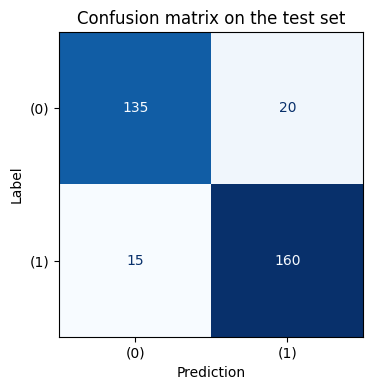

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(test_y, test_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["(0)", "(1)"],
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Confusion matrix on the test set")
ax.set_xlabel("Prediction")
ax.set_ylabel("Label")
plt.tight_layout()
plt.show()

## 5. Analyze Prediction Errors

All test examples where the predicted label differs from the recorded label are displayed, including false positives and false negatives. The review ID can be used to check the full text and the recorded label.

The reported metrics are based on the selected test set. The proportion of reviews containing profanity may differ in real-world data. The dataset includes reviews of apps and games, and performance on reviews of physical products was not evaluated separately.

In [15]:
for label in (0, 1):
    indices = [i for i, actual in enumerate(test_y)
               if actual == label and test_pred[i] != label]
    indices.sort(key=lambda i: abs(test_scores[i] - threshold), reverse=True)
    for i in indices:
        print(f'{test_ids[i]} | метка {test_y[i]} → прогноз {test_pred[i]}'
              f' | score {test_scores[i]:.3f} | {test_text[i][:220]}')

pla034591pla | метка 0 → прогноз 1 | score 0.642 | ал кеттик
pla080842pla | метка 0 → прогноз 1 | score 0.641 | неге қотарлмайды
pla069133pla | метка 0 → прогноз 1 | score 0.543 | менің талғамымдағы ойын емес
pla055659pla | метка 0 → прогноз 1 | score 0.540 | бұл программаны тартпасаң гугл плей дан тартқан бір неше оиындарың ашылмаиды екен.🤔🤔
pla093351pla | метка 0 → прогноз 1 | score 0.539 | айман йутуп не жазу мынау 🖓🖓
pla003387pla | метка 0 → прогноз 1 | score 0.535 | инстаграм неге ошип кала береді
pla100917pla | метка 0 → прогноз 1 | score 0.528 | сбоит синхронизация с amazfit bip.
pla113902pla | метка 0 → прогноз 1 | score 0.492 | сорлы екенсіңдер ағылшын тілін білмесеңдер
pla075299pla | метка 0 → прогноз 1 | score 0.490 | гарена топ алмаз берш
pla131372pla | метка 0 → прогноз 1 | score 0.488 | сасық канал боқтың исі шығады
pla076598pla | метка 0 → прогноз 1 | score 0.486 | жазылып болмайт сет норм мегабайтпененде уайфайменендн жаздым
pla038208pla | метка 0 → прогноз 1 | score 0.

### Error Analysis

- **Neutral phrase flagged (`pla034591pla`, score 0.642).** The phrase “ал кеттик” (“let’s go”) was predicted as class `1`, although it contains no profanity. The score was well above the 0.46 threshold. One possible explanation is that the model gave too much weight to short character sequences that also occur in profane training examples. Adding more short, neutral comments to the training set could help.
- **Masked profanity missed (`pla030335pla`, score 0.362).** The review contains “к*т”, a masked form of “көт”, but was predicted as class `0`. The asterisk changes the character n-grams, which can make the masked spelling harder to recognize. Adding labeled examples with different masking patterns could improve recall.
- **Inconsistent label for an insult (`pla071821pla`, score 0.435).** The review “қосылмайды ғой мал” was predicted as class `0`, while the recorded label was `1`. The word “мал” is used as an insult here. 

In moderation, false positives can hide legitimate feedback, while false negatives can leave profanity visible.

## 6. Save and Predict

In [16]:
import joblib

joblib.dump({'pipeline': model, 'threshold': threshold}, 'model.joblib', compress=3)
print('Сохранено: model.joblib')

Сохранено: model.joblib


In [17]:
import unicodedata
import joblib

saved = joblib.load('model.joblib')

def predict(text):
    cleaned = ' '.join(unicodedata.normalize('NFKC', text).casefold().split())
    if not cleaned:
        raise ValueError('Введи непустой отзыв')
    score = float(saved['pipeline'].predict_proba([cleaned])[0, 1])
    return {'label': int(score >= saved['threshold']), 'score': round(score, 4)}

print(predict('Құлаққаптың дыбысы да микрофоны да жақсы екен.'))

{'label': 0, 'score': 0.2458}
